# Oil products demand — 02 Research & results: US jet fuel

**Question.** Can a gradient-boosted tree, fed lagged demand and a physical indicator readable the next day, the kerosene burned by the commercial jets leaving US airports, forecast monthly US jet fuel demand up to twelve months ahead better than a seasonal naive?

**State of this run.** OpenSky's flights were online only from 20 December 2022 when the index was downloaded, so the index starts in 2023 and its year-on-year change, the form the model uses, from January 2024. For most of the backtest the model runs on lagged demand alone; the test of the index is the window where it exists (section 7).

This notebook reads the point-in-time dataset built in `01_data_jet.ipynb` and the walk-forward backtests written by `python -m src.model`. It performs no data operation of its own.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, model, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": .3})

LABEL = {"xgboost": "xgboost", "naive": "seasonal naive", "last": "last value"}
STYLE = {"xgboost": dict(color="C1"), "naive": dict(color="C0", ls="--"), "last": dict(color="0.5", ls=":")}

In [2]:
df, lag = data.dataset("jet"), c.DEMAND_LAG["jet"]           # the panel of notebook 01
bt = sql.query("SELECT * FROM backtest WHERE product = 'jet'")  # one row per origin and horizon
marked = model.scored(bt)                                     # target published, no 2020 in origin, target or reference
print(f"drivers in the dataset: {list(df.columns.drop('demand')) or 'none yet'}")

drivers in the dataset: ['burn']


## 1. Key findings

In [3]:
# WAPE in %, averaged over the twelve horizons: the model against its two free benchmarks
headline = model.wape(bt).rename(LABEL).to_frame("WAPE, %").T
headline["gain on seasonal naive, %"] = 100 * (1 - headline["xgboost"] / headline["seasonal naive"])
headline["gain on last value, %"] = 100 * (1 - headline["xgboost"] / headline["last value"])
print(f"walk-forward backtest, {marked['origin'].nunique()} monthly origins {marked['origin'].min():%b %Y} to {marked['origin'].max():%b %Y}")
headline

walk-forward backtest, 125 monthly origins Jan 2015 to Jul 2026


,xgboost,seasonal naive,last value,"gain on seasonal naive, %","gain on last value, %"
"WAPE, %",4.42,4.99,5.67,11.35,22.03


In [4]:
# the test that matters: the same backtest without the burn index, over every origin and over those where the index exists
ablation = sql.query("SELECT * FROM ablation WHERE product = 'jet'")
seeds = sql.query("SELECT * FROM seeds WHERE product = 'jet'")
runs = pd.concat([seeds, ablation[ablation["variant"] == "all drivers"].assign(seed=model.PARAMS["random_state"])])  # four seeds
mean = ablation.groupby(["since", "variant"])["xgboost"].mean().unstack()
mean["index helps by, points"] = mean["lags only"] - mean["all drivers"]
mean["seed noise, points"] = runs.groupby(["since", "seed"])["xgboost"].mean().groupby("since").agg(lambda s: s.max() - s.min())
mean

variant,all drivers,lags only,"index helps by, points","seed noise, points"
since,,,,
2015-01-01,4.42,4.46,0.03,0.05
2024-01-01,2.62,2.62,-0.00,0.10


- **The model beats both free benchmarks, on lagged demand alone.** Over 125 monthly origins from January 2015 to July 2026, outside 2020, its WAPE is 4.42% against 4.99% for the seasonal naive and 5.67% for the last value: 11% better than the naive. The gain is at one to five months (3.0% against 4.5% one month ahead) and at eleven and twelve, where the naive has to reach back two years.
- **Most of the gain is a trend the naive cannot see.** The naive repeats last year and was 4% too low on average, through the growth years before 2019 and the recovery after 2021. The model reads recent growth; in 2025 and 2026, with demand back at its 2019 level and growth near zero, it is level with the naive.
- **The burn index adds nothing.** Where it exists, from January 2024 (31 marked origins), the error with and without it is the same to 0.003 points, against a seed noise of 0.10; by horizon the differences change sign and stay mostly inside the noise.
- **Why: its growth rate measures OpenSky's network as much as demand.** On the 30 months it can be compared, the index's year-on-year growth correlates 0.20 with EIA's, against 0.62 for EIA's own weekly estimate, and misses it by 3.9 points on average against 2.4. From May to December 2025 it runs 3 to 8 points above demand, as OpenSky placed more flights.

## 2. The forecasting problem

- **Target.** Monthly US kerosene-type jet fuel product supplied, EIA Petroleum Supply Monthly, kb/d.
- **Origin.** The last day of month *t*. The information set is everything published by then: demand up to *t − 2* (the Petroleum Supply Monthly comes out at the end of the second month after), and the burn index up to the day before.
- **Horizon.** Months *t+1* to *t+12*, forecast directly: one model per step, each trained on its own target, never a forecast fed back as an input.
- **Benchmarks.** *Seasonal naive*: the same calendar month in the latest year already published at the origin. *Last value*: the newest published print, held flat. Both are free and use the same information set.
- **Model.** `XGBRegressor` on the log deviation from the seasonal naive, `y = log demand(t+step) − log naive`. The forecast is the naive times `exp(prediction)`. If the model learns nothing it predicts zero and returns the naive.
- **Evaluation.** Expanding-window walk-forward: at every month end since January 2015 the twelve models are refitted on what was published by then, and the forecasts are marked later against the published outcome. WAPE (sum of absolute errors over sum of actuals) is the headline; MAE and RMSE in kb/d; bias.
- **2020 is left out** of training and of the headline (`config.EXCLUDE`). The backtest still forecasts through it; section 6 shows those forecasts apart.

In [5]:
# one past origin, used for the walk-through below: everything published by 31 December 2024
origin = pd.Timestamp("2024-12-01")
months = pd.date_range(origin + pd.DateOffset(months=1), periods=model.HORIZON, freq="MS", name="target month")
reference = [m - pd.DateOffset(months=model.back(step, lag)) for step, m in enumerate(months, 1)]
print(f"newest demand print at the origin: {origin - pd.DateOffset(months=lag):%B %Y}")
pd.DataFrame({"step": range(1, model.HORIZON + 1), "seasonal naive repeats": reference}, index=months).T

newest demand print at the origin: October 2024


target month,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01
step,1,2,3,4,5,6,7,8,9,10,11,12
seasonal naive repeats,2024-01-01 00:00:00,2024-02-01 00:00:00,2024-03-01 00:00:00,2024-04-01 00:00:00,2024-05-01 00:00:00,2024-06-01 00:00:00,2024-07-01 00:00:00,2024-08-01 00:00:00,2024-09-01 00:00:00,2024-10-01 00:00:00,2023-11-01 00:00:00,2023-12-01 00:00:00


Steps 11 and 12 reach back two years: at the end of December 2024 the figures for November and December 2024 are not out yet. A naive that used them would be looking ahead.

## 3. Demand: level, seasonality, persistence

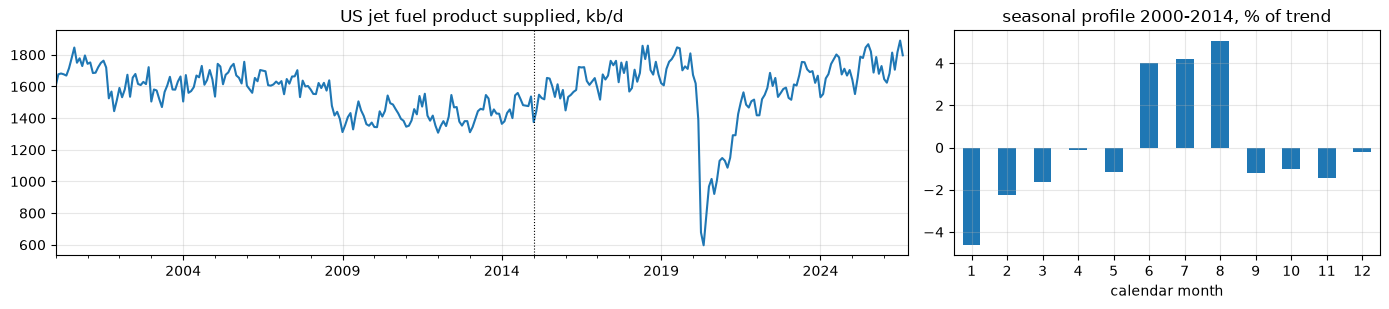

In [6]:
history = df.loc[df.index < c.BACKTEST_START, "demand"]  # only what precedes the backtest informs the design

# seasonal profile: each month against its centred twelve-month average, in %
profile = 100 * (history / history.rolling(12, center=True).mean() - 1)
profile = profile.groupby(profile.index.month).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.2), width_ratios=[2, 1])
df.loc[c.SAMPLE_START:, "demand"].plot(ax=axes[0], title="US jet fuel product supplied, kb/d")
axes[0].axvline(pd.Timestamp(c.BACKTEST_START), color="k", lw=.8, ls=":"); axes[0].set_xlabel("")
profile.plot.bar(ax=axes[1], rot=0, title="seasonal profile 2000-2014, % of trend"); axes[1].set_xlabel("calendar month")
plt.tight_layout();

In [7]:
# persistence before the backtest: autocorrelation of the level and of the year-on-year log change
yoy = np.log(history).diff(12)
pd.Series({"level, 1 month": history.autocorr(1), "level, 12 months": history.autocorr(12),
           "year-on-year, 1 month": yoy.autocorr(1), "year-on-year, 12 months": yoy.autocorr(12),
           "seasonal swing, % of trend": profile.max() - profile.min()}).to_frame("jet").T

,"level, 1 month","level, 12 months","year-on-year, 1 month","year-on-year, 12 months","seasonal swing, % of trend"
jet,0.85,0.74,0.63,-0.23,9.69


In [8]:
# has demand come back? Each year against 2019, the last year before the pandemic, %
yearly = df["demand"].dropna().resample("YE").mean()
yearly.index = yearly.index.year
(100 * (yearly.loc[2015:] / yearly.loc[2019] - 1)).to_frame("% of 2019").T

month,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% of 2019,-11.18,-7.36,-3.52,-2.05,0.00,-38.16,-21.47,-10.53,-5.16,-3.03,-0.35,0.27


- **A trend, then a hole, then a recovery.** Demand was 11% below its 2019 level in 2015 and grew every year to 2019; it lost 38% in 2020 and only came back to the 2019 level in 2025. A naive that repeats last year is behind in every growth year: that is the room the model has.
- **Seasonality is moderate**: a swing of about 10% of trend, the summer peak. The seasonal naive captures it.
- **Growth persists**: the year-on-year change has an autocorrelation of 0.63 from one month to the next before 2015. Recent growth says something about next month's, which is what the lagged features use.

## 4. Features

Everything enters in year-on-year terms, so the model sees growth rather than levels: the last twelve published demand prints (`yoy_lag`) and the 28-day mean of the burn index as readable at the origin against its value a year earlier. That growth exists from January 2024; before, the value is missing and XGBoost sends it down a default branch learned in training.

In [9]:
X, y = model.features(df, lag, step=12)
X.loc[origin].to_frame(f"origin {origin:%b %Y}").T  # one row: the information set at the origin

,yoy_lag2,yoy_lag3,yoy_lag4,yoy_lag5,yoy_lag6,yoy_lag7,yoy_lag8,yoy_lag9,yoy_lag10,yoy_lag11,yoy_lag12,yoy_lag13,burn
origin Dec 2024,0.01,-0.01,0.04,0.03,0.01,0.04,0.04,0.02,0.02,0.00,0.05,0.02,0.01


In [10]:
# the target at this origin by hand: log of December 2025 over December 2023, the naive's reference
target = origin + pd.DateOffset(months=12)
by_hand = np.log(df.loc[target, "demand"] / df.loc[target - pd.DateOffset(months=model.back(12, lag)), "demand"])
assert abs(by_hand - y.loc[origin]) < 1e-12
by_hand

np.float64(0.03591790276459843)

In [11]:
# what the driver on that row describes, and when it was published: read from the stored panel
info = sql.query(f"""
    SELECT variable, period_end, available_at, month_end AS origin, value
    FROM panel WHERE product = 'jet' AND month = DATE '{origin:%Y-%m-%d}'
""")
assert (info["available_at"] <= info["origin"]).all()
info

,variable,period_end,available_at,origin,value
0,burn,2024-12-30,2024-12-31,2024-12-31,"1,096.80"


## 5. Training and tuning without look-ahead

**Training rows.** A row can be used at an origin only if its *target* had been published by then. For the twelve-month model that removes the last fourteen months before the origin, not twelve. Rows whose origin, target or naive reference falls in 2020 are left out of training: the model is not asked to learn a lockdown.

In [12]:
rows = model.trainable(y, step=12, product="jet", origin=origin)
last = X.index[rows].max()
assert last + pd.DateOffset(months=12 + lag) <= origin  # its target was published by the origin
pd.DataFrame({"training rows": [rows.sum()], "first origin": [X.index[rows].min()], "last origin": [last],
              "its target month": [last + pd.DateOffset(months=12)],
              "target published by the end of": [last + pd.DateOffset(months=12 + lag)]})

,training rows,first origin,last origin,its target month,target published by the end of
0,238,2001-01-01,2023-10-01,2024-10-01,2024-12-01


In [13]:
# one model per horizon, each with its own training rows; and at the first backtest origin, January 2015
first = pd.Timestamp(c.BACKTEST_START)
pd.DataFrame({when: {step: model.trainable(model.features(df, lag, step)[1], step, "jet", at).sum() for step in range(1, model.HORIZON + 1)}
              for when, at in (("origin Dec 2024", origin), ("first origin, Jan 2015", first))}).T

,1,2,3,4,5,6,7,8,9,10,11,12
origin Dec 2024,261,260,259,258,257,256,255,254,253,252,239,238
"first origin, Jan 2015",166,165,164,163,162,161,160,159,158,157,155,155


**Tuning.** Eight parameter sets, chosen once at the first backtest origin by expanding-window cross-validation on the data published by then. The backtest years play no part in the choice.

In [14]:
fit_rows = model.trainable(y, 12, "jet", first)
cv = pd.DataFrame(model.GRID)
cv["cv rmse, %"] = [100 * np.sqrt(model.cv_score(X[fit_rows], y[fit_rows], 12, lag, params)) for params in model.GRID]
cv.sort_values("cv rmse, %")

,learning_rate,max_depth,n_estimators,"cv rmse, %"
6,0.10,5,200,10.83
7,0.10,5,600,10.84
2,0.03,5,200,11.12
0,0.03,3,200,11.12
3,0.03,5,600,11.17
1,0.03,3,600,11.36
4,0.10,3,200,11.38
5,0.10,3,600,11.39


In [15]:
assert model.tuned("jet") == model.tune(df, "jet", first)  # what the backtest stored is the best line above
sql.query("SELECT * FROM params WHERE product = 'jet'")

,product,learning_rate,max_depth,n_estimators
0,jet,0.10,5,200


**The direct test for look-ahead.** Delete from the dataset everything that was not published at the origin, the demand prints of the last two months and every later row, and forecast again. If any step of the pipeline read the future, the forecast would change.

In [16]:
path = model.forecast(df, "jet", origin, model.tuned("jet"))
known = df.loc[:origin].copy()
known.loc[known.index > origin - pd.DateOffset(months=lag), "demand"] = np.nan  # not published yet at the origin
assert (model.forecast(known, "jet", origin, model.tuned("jet")) == path).all()
pd.DataFrame({"xgboost": path, "seasonal naive": model.seasonal_naive(df, lag, origin), "actual": df["demand"].reindex(path.index)}).T

,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01
xgboost,"1,536.46","1,607.74","1,683.68","1,611.32","1,708.23","1,809.30","1,832.14","1,749.19","1,725.11","1,736.25","1,655.44","1,673.02"
seasonal naive,"1,532.00","1,552.00","1,651.00","1,678.00","1,742.00","1,772.00","1,802.00","1,784.00","1,676.00","1,712.00","1,623.00","1,668.00"
actual,"1,643.00","1,552.00","1,655.00","1,788.00","1,780.00","1,846.00","1,867.00","1,820.00","1,688.00","1,786.00","1,680.00","1,729.00"


## 6. Walk-forward backtest

The same procedure from every month end since January 2015, stored by `python -m src.model`.

In [17]:
# integrity of the stored backtest: every target is after its origin, and every naive reference had been published by the origin
def months_between(start, end):
    return (end.dt.year - start.dt.year) * 12 + end.dt.month - start.dt.month

assert (months_between(bt["origin"], bt["month"]) == bt["step"]).all()
assert (months_between(bt["reference"], bt["origin"]) >= lag).all()
pd.Series({"origins": bt["origin"].nunique(), "first origin": bt["origin"].min(), "last origin": bt["origin"].max(),
           "forecasts": len(bt), "marked": bt["actual"].notna().sum(), "marked outside 2020": len(marked)}).to_frame("jet").T

,origins,first origin,last origin,forecasts,marked,marked outside 2020
jet,140,2015-01-01 00:00:00,2026-08-01 00:00:00,1680,1602,1291


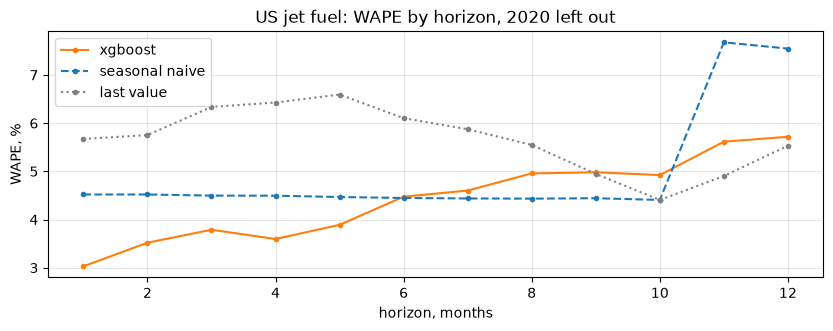

In [18]:
# error by horizon
by_step = model.score(marked)
ax = plt.gca()
for name in model.FORECASTS:
    by_step["wape"][name].plot(ax=ax, marker="o", ms=3, label=LABEL[name], **STYLE[name])
ax.set_title("US jet fuel: WAPE by horizon, 2020 left out"); ax.set_xlabel("horizon, months"); ax.set_ylabel("WAPE, %"); ax.legend();

In [19]:
# every metric by horizon. MAE and RMSE in kb/d, WAPE and bias in %
by_step.round(2)

mae                  rmse                  wape               bias            
     xgboost  naive   last xgboost  naive   last xgboost naive last xgboost naive  last
step                                                                                   
1      50.52  75.36  94.56   75.88  99.99 106.98    3.03  4.52 5.67   -1.18 -4.02 -0.98
2      58.74  75.45  96.02   90.38 100.24 118.30    3.52  4.52 5.75   -1.68 -4.02 -1.23
3      63.27  75.10 105.82  100.24 100.10 130.28    3.79  4.50 6.34   -2.04 -3.99 -1.53
4      60.11  75.12 107.44   93.80 100.32 133.52    3.60  4.49 6.43   -2.06 -3.98 -1.81
5      65.07  74.73 110.29   97.90 100.13 130.56    3.89  4.47 6.59   -2.39 -3.95 -2.09
6      74.85  74.41 102.10  111.20 100.04 120.06    4.47  4.45 6.10   -2.90 -3.93 -2.36
7      76.99  74.26  98.28  112.86 100.12 113.69    4.60  4.44 5.87   -3.10 -3.91 -2.68
8      82.97  74.21  92.87  118.11 100.29 110.59    4.96  4.43 5.55   -3.46 -3.90 -3.06
9      83.43  74.42  82.86  116.78 100.63 106.40    4.98  4.44 4.95   -3.56 -3.91 -3.52
10     82.50  73.85  73.85  111.03 100.25 100.25    4.92  4.41 4.41   -3.23 -3.87 -3.87
11     94.93 129.79  82.89  133.30 156.00 102.16    5.61  7.68 4.90   -4.08 -7.23 -3.41
12     96.82 127.80  93.71  135.34 153.93 114.07    5.72  7.55 5.53   -4.78 -7.46 -3.58

- **The gain is at short horizons.** One month ahead the model's WAPE is 3.0% against 4.5% for the naive, five months ahead 3.9% against 4.5%. From six to ten months the two are level, the model slightly behind at eight to ten (4.9% to 5.0% against 4.4%). At eleven and twelve months the naive has to repeat a month two years old and the model wins again (5.6% to 5.7% against 7.6% to 7.7%).
- **Both forecasts are too low on average**, the naive by 4% at every horizon, the model by 1% at one month rising to 5% at twelve: demand grew over most of the sample and forecasts that lean on the past lag it.
- **The last value is the worst benchmark** at short horizons, because of the seasonality; at ten months it is the naive itself.

In [20]:
# by target year, WAPE %. This table keeps 2020 and the months that reference it, which the headline leaves out
everything = model.scored(bt, shocks=True)
everything = everything.assign(year=everything["month"].dt.year)
by_year = model.score(everything, "year")["wape"].rename(columns=LABEL)
by_year

,xgboost,seasonal naive,last value
year,,,
2015,3.47,5.10,5.93
2016,3.62,4.98,5.78
2017,3.46,4.84,5.12
2018,2.35,3.70,5.51
2019,3.25,3.28,5.22
2020,63.22,62.34,54.89
2021,34.06,35.59,25.90
2022,17.09,16.15,8.69
2023,7.39,7.58,5.84


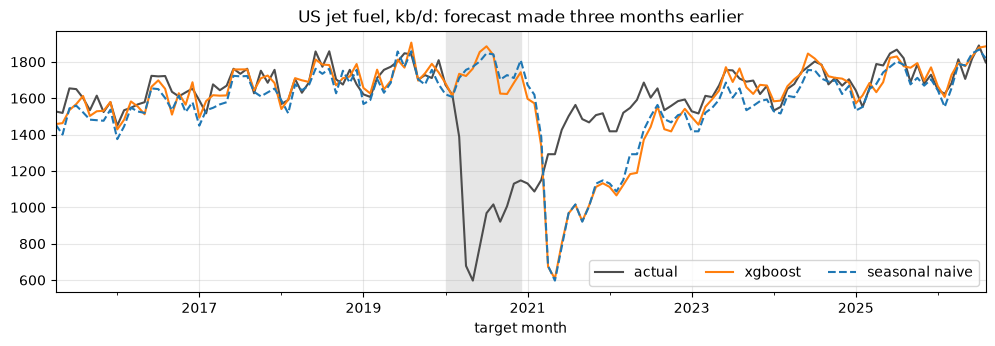

In [21]:
# actual against forecast, three months ahead, with 2020 shaded
three = everything[everything["step"] == 3].set_index("month")
ax = three["actual"].plot(color="0.3", label="actual", figsize=(12, 3.4))
three["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
three["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
ax.axvspan(pd.Timestamp(c.COVID[0]), pd.Timestamp(c.COVID[1]), color="0.9")
ax.set_title("US jet fuel, kb/d: forecast made three months earlier"); ax.set_xlabel("target month"); ax.legend(ncol=3);

origins where the model beat the naive: 63%


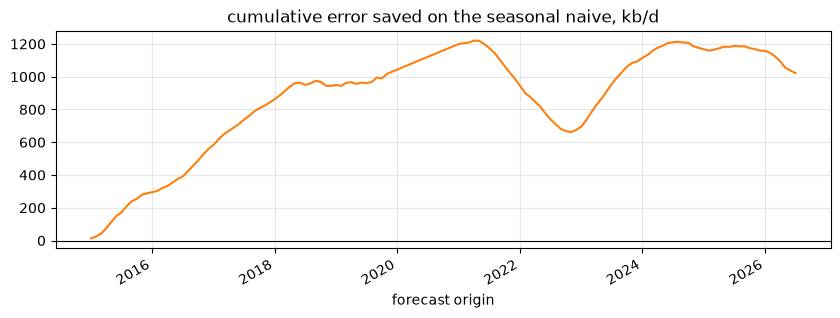

In [22]:
# where the model earns or loses against the naive: absolute error saved, cumulated over forecast origins
saved = ((marked["naive"] - marked["actual"]).abs() - (marked["xgboost"] - marked["actual"]).abs()).groupby(marked["origin"]).mean()
ax = saved.cumsum().plot(color="C1", title="cumulative error saved on the seasonal naive, kb/d")
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("forecast origin")
print(f"origins where the model beat the naive: {(saved > 0).mean():.0%}")

- **The model wins in the growth years**: 3.5% against 5.1% in 2015, 2.4% against 3.7% in 2018, 2.1% against 3.3% in 2024. In 2019, 2025 and 2026, when demand was flat, it is level with the naive, a little behind in 2026 (2.6% against 2.3%).
- **2020 to 2022 are lost for everyone**: 63% in 2020, 34% in 2021, 16-17% in 2022, with the last value the least bad in 2021-2022 because it is the only forecast that does not repeat a lockdown month. Excluding 2020 from the headline mostly removes forecasts the last value wins, in 2021-2022; against the naive the model is ahead in 2021 and 2023 and behind in 2022.
- The cumulative line rises in episodes, 2015-2018 and 2024, and is flat in between: the model beats the naive from 63% of the origins.

## 7. The burn index: does it help, and against what bar?

Two tests, both out-of-sample. **The gain by horizon**: the backtest rerun without the burn index, the same parameters, horizon by horizon, read against the seed band, the spread of the same model under three other random seeds. **The index against the EIA weekly figure**: the weekly Petroleum Status Report is the free nowcast the index competes with, out a week after the fact against a day.

step                              1     2     3     4     5    6     7     8     9     10    11    12
                    since                                                                            
burn index helps by 2015-01-01  0.10 -0.03 -0.08  0.01 -0.05 0.07 -0.00 -0.12  0.03  0.07  0.14  0.24
                    2024-01-01 -0.03  0.12  0.07 -0.07 -0.04 0.31  0.31  0.10 -0.12 -0.20 -0.39 -0.08
seed noise          2015-01-01  0.14  0.18  0.23  0.10  0.11 0.14  0.28  0.17  0.44  0.40  0.17  0.19
                    2024-01-01  0.13  0.30  0.11  0.06  0.21 0.07  0.45  0.47  0.28  0.73  0.23  0.19

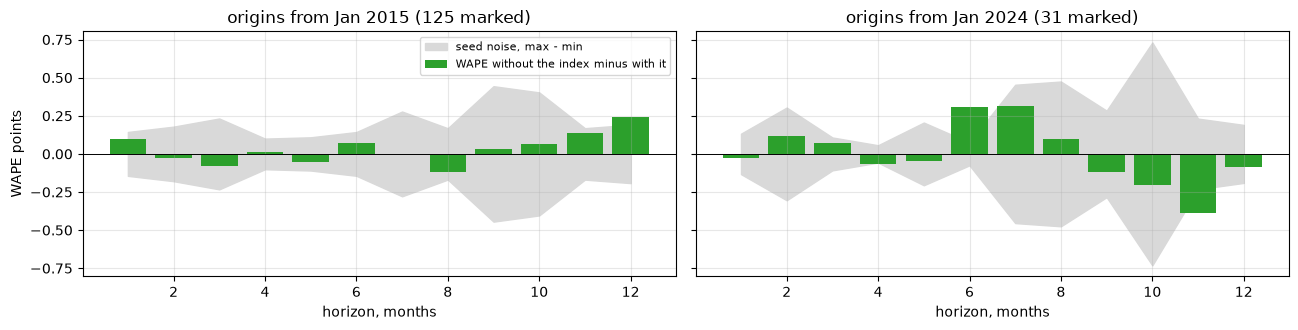

In [23]:
band = runs.groupby(["since", "step"])["xgboost"].agg(lambda s: s.max() - s.min())
steps = ablation.pivot_table(index=["since", "step"], columns="variant", values="xgboost")
gain = steps["lags only"] - steps["all drivers"]
windows = gain.index.get_level_values("since").unique()
fig, axes = plt.subplots(1, len(windows), figsize=(13, 3.4), sharey=True, squeeze=False)
for ax, since in zip(axes[0], windows):
    origins = marked.loc[marked["origin"] >= since, "origin"].nunique()
    ax.bar(gain[since].index, gain[since], color="C2", label="WAPE without the index minus with it")
    ax.fill_between(band[since].index, -band[since], band[since], color="0.85", zorder=0, label="seed noise, max - min")
    ax.axhline(0, color="k", lw=.7); ax.set_xlabel("horizon, months"); ax.set_title(f"origins from {since:%b %Y} ({origins} marked)")
axes[0, 0].set_ylabel("WAPE points"); axes[0, 0].legend(fontsize=8)
plt.tight_layout();
pd.DataFrame({"burn index helps by": gain, "seed noise": band}).unstack("since").T.round(2)

,correlation with monthly,"mean absolute gap, points",months
weekly,0.62,2.45,30.00
burn,0.20,3.85,30.00


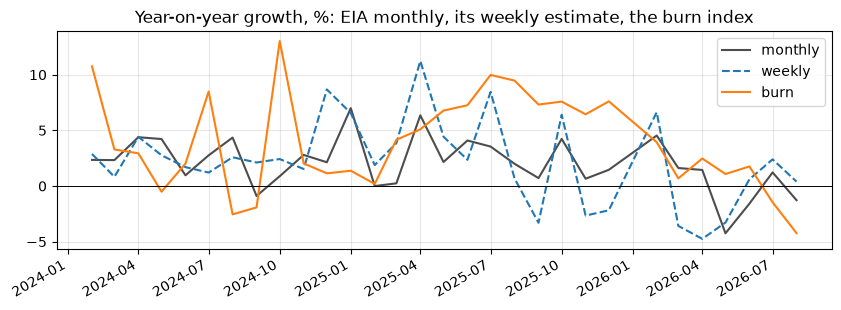

In [24]:
# the index against the bar set by the weekly figure: year-on-year growth, the terms the model sees, of the weekly
# estimate averaged over each month and of the index at each month end, against the monthly figure, on the months all three exist
weekly = sql.query("SELECT period_end, value FROM predictors WHERE product = 'jet' AND variable = 'product_supplied_weekly'")
weekly = weekly.set_index(pd.to_datetime(weekly["period_end"]))["value"].resample("MS").mean()
monthly = df["demand"].dropna()
growth = pd.DataFrame({"monthly": np.log(monthly).diff(12), "weekly": np.log(weekly).diff(12)}).dropna()
growth = growth[~(model.excluded(growth.index, "jet") | model.excluded(growth.index - pd.DateOffset(months=12), "jet"))]  # no 2020 on either side
burn = data.predictors("jet")["burn"]  # the 28-day mean the model reads, lost days left out
burn = burn.reindex(monthly.index + pd.offsets.MonthEnd(0) - pd.Timedelta(days=1)).set_axis(monthly.index)  # to the day before each month end
growth["burn"] = np.log(burn).diff(12)
growth = growth.dropna()
ax = (100 * growth).plot(style={"monthly": "-", "weekly": "--", "burn": "-"}, color={"monthly": "0.3", "weekly": "C0", "burn": "C1"},
                         title="Year-on-year growth, %: EIA monthly, its weekly estimate, the burn index")
ax.axhline(0, color="k", lw=.7); ax.set_xlabel("")
pd.DataFrame({name: {"correlation with monthly": growth[name].corr(growth["monthly"]),
                     "mean absolute gap, points": 100 * (growth[name] - growth["monthly"]).abs().mean(),
                     "months": len(growth)} for name in growth.columns.drop("monthly")}).T

- **The full window says nothing about the index.** Before 2024 the index is missing from every row, yet the two runs differ: each tree draws 80% of the columns at random, and an extra column, even an empty one, changes the draw. The left panel is therefore seed noise by construction, and it looks like it.
- **The window where the index exists says it does not help.** From January 2024, 31 marked origins one month ahead and 20 twelve months ahead, the index improves the error at six and seven months by 0.3 points and worsens it at eleven by 0.4: the signs alternate, and the average change is zero.
- **Its growth rate is not demand's.** Against the monthly figure, the index's year-on-year growth correlates 0.20 and misses by 3.9 points on average, against 0.62 and 2.4 for EIA's weekly estimate on the same 30 months. The chart shows why: the index jumps in February and October 2024, the mirror of OpenSky's thin coverage in February 2023 and of the days it lost in October 2023, and runs 3 to 8 points above demand from May to December 2025, when OpenSky placed more flights (notebook 01, section 9).
- **The test is short.** Twenty to thirty-one origins is little, and the index has only one clean year of year-on-year history. The verdict is "no evidence", not "evidence of nothing"; OpenSky's older flights would give the index eight more years to be judged on.

## 8. Current forecast

The same models fitted at the latest origin, with the parameters the backtest chose.

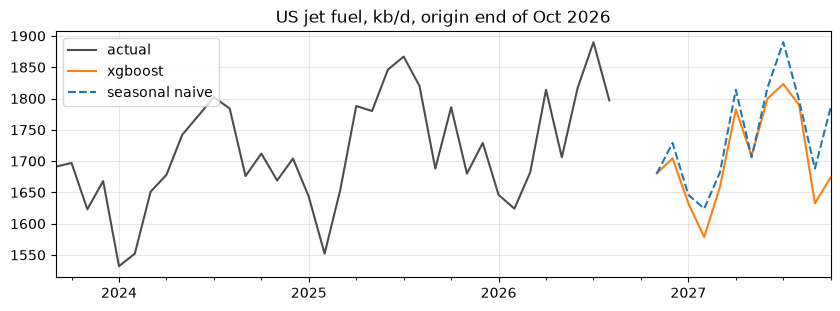

In [25]:
last_origin = df.index[-1]
latest = pd.DataFrame({"xgboost": model.forecast(df, "jet", last_origin, model.tuned("jet")),
                       "naive": model.seasonal_naive(df, lag, last_origin)})
ax = df["demand"].dropna().iloc[-36:].plot(color="0.3", label="actual")
latest["xgboost"].plot(ax=ax, label="xgboost", **STYLE["xgboost"])
latest["naive"].plot(ax=ax, label="seasonal naive", **STYLE["naive"])
ax.set_title(f"US jet fuel, kb/d, origin end of {last_origin:%b %Y}"); ax.set_xlabel(""); ax.legend();

In [26]:
# the forecast as a deviation from the seasonal naive, in %
(100 * (latest["xgboost"] / latest["naive"] - 1)).to_frame("xgboost over naive, %").T

,2026-11-01,2026-12-01,2027-01-01,2027-02-01,2027-03-01,2027-04-01,2027-05-01,2027-06-01,2027-07-01,2027-08-01,2027-09-01,2027-10-01
"xgboost over naive, %",0.02,-1.42,-0.82,-2.81,-1.36,-1.74,0.13,-0.95,-3.54,-0.41,-3.30,-6.26


From the end of October 2026, the model sits at or below the seasonal naive over the coming year: within 1% in five months of twelve, 1.4% to 3.5% under in six, 6% under at twelve months. It reads the mostly negative year-on-year prints of May to August 2026 and extends them. Given section 6, the first months of the adjustment have some support in the backtest; beyond six months the naive is the number to quote.

## 9. Limitations

- **Not a vintage backtest.** Publication delays are respected, revisions are not: EIA keeps only its latest figures, and OpenSky recomputes its flights when it changes its processing (August 2026).
- **The index is short and drifts.** It starts in December 2022, its growth rate from January 2024. Its level grows 3% to 5% faster than demand over 2023-2026 because OpenSky's coverage grows, and the lost-day rule only partly catches the days OpenSky degraded without saying so (notebook 01).
- **The index is a model of a model.** Great-circle distances, one OpenAP flight profile per type at 85% of MTOW, an aircraft database from one date, departures only: each choice moves the level, and the level is not what the model uses. What it uses, the growth rate, is what coverage contaminates.
- **Small sample.** About 300 months and 125 marked origins, with overlapping twelve-month targets: neighbouring errors are correlated, the differences between forecasts are not tested formally.
- **2020.** Excluded from training and from the headline by an explicit rule; the by-year table shows it.
- **One benchmark family.** Seasonal naive and last value. An ETS or SARIMA model would be a fairer statistical rival.
- **Apparent consumption.** EIA product supplied is disappearance from primary stocks, not fuel burned: airline and airport inventories sit between the two, which is the gap the index was meant to close and cannot see.

## 10. Conclusion

On US jet fuel, a gradient-boosted tree fed lagged demand **does** forecast monthly demand better than a seasonal naive, by 11% on average, at one to five months and at eleven to twelve. The gain comes from growth the naive cannot see, and it fades when demand is flat, as in 2025-2026.

The kerosene burn index does not improve it. Its level follows EIA within about 5% once scaled, but the model needs a growth rate, and the index's growth rate measures OpenSky's coverage as much as airline activity: it correlates less with demand than EIA's own weekly estimate, which is free and a week old.

For a desk, the weekly figure remains the nowcast to beat. The index could still earn its place as a daily, D+1 read of the level, after a coverage correction (a fixed panel of airports or receivers), and once OpenSky's flights from 2016 are back online to judge it over more than one year.